## Exploring Vector Embeddings with Gemini Embedding Model

##### In this notebook, I would like to explore how text is transformed into tokens and vector embeddings; how it looks like in a vector space. I will build upon this foundation and concept to create a 'system' that takes in documents, convert its text into vector embeddings and store them in a vector database

### Step 1: Importing required packages

In [ ]:
%pip install -q google-genai

In [8]:
from google import genai
from google.genai import types
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display

### Step 2: Setting the API Key

In [3]:
import os
from dotenv import load_dotenv, find_dotenv
from google import genai
from google.genai import types

# Loading GEMINI_API_KEY from my local .env file
load_dotenv(find_dotenv())

print('API Key found: ', bool(os.environ.get('GEMINI_API_KEY')))

api_key = os.environ.get('GEMINI_API_KEY')

# Check
if not api_key:
    raise RuntimeError(
        'GOOGLE_API_KEY not found'
        'Check the env file or add it'
    )

# Initializing the client
client = genai.Client(api_key = api_key)


API Key found:  True


### Step 3: Generating Embeddings

##### Here I will first use a few sentences to generate vector embeddings. In the next project, I will generate embeddings from text documents

In [4]:
# First I will suggest text to be converted into embeddings using a list of strings
# I am really interested to test some relationships, for example, how similar is sleeping late relate to code debugging, or singing vocals related to a weekend
# These are my assumptions, but let me see how it goes. Hooah!

text = [
    'I like listening and singing vocal acapella',
    'My code has alot of bugs',
    'Asernal is the best team in the Premier League right now',
    'There is a bit of soreness in my eyes, I slept very late',
    '"What do you do on a weekend?"',
    'Sometimes getting away in nature is the best thing to do'
]

# Generating the results using gemini embedding model > gemini-embedding-001
# The model takes in text as input and give embeddings as output
# Input token limit: 2,048; output dimensionality size: 128-3072, I will use the recommended 768

results = client.models.embed_content(
    model = 'gemini-embedding-001',
    contents = text,
    config = types.EmbedContentConfig(task_type = 'SEMANTIC_SIMILARITY', outputDimensionality = 768)
)

# Printing the embeddings
for text, embedding_obj in zip(text, results.embeddings):
    embedding = embedding_obj.values
    print('Text: ', text)
    print('Embedding length: ', len(embedding))
    print('Embedding: ', embedding)
    print('-'* 50)


Text:  I like listening and singing vocal acapella
Embedding length:  768
Embedding:  [-0.009845125, -0.022167798, 0.010309894, -0.0952525, -0.003906366, 0.0038616888, 0.020513365, 0.0019626885, 0.0009745196, 0.0029093148, 0.010245282, -0.00052931067, -0.014192432, 0.024293886, 0.12529331, -0.022259051, -0.011720081, -0.00510945, 0.005912706, -0.013566733, -0.0032460915, -0.011794468, 0.001617725, -0.007646803, -0.024759244, 0.011325183, 0.028323285, 0.012371737, 0.033830144, -0.012862945, 0.0075709475, 0.020328216, -0.0076597757, 0.0020788857, 0.026011214, 0.013377595, 0.02711459, 0.0038788442, 0.006746544, 0.020848116, 0.0050688316, -0.00031477868, -0.004964962, -0.009359464, 0.0050354726, -0.020282246, -0.0035785413, -0.011911962, -0.000105607825, 0.028858388, 0.008280349, -0.028401572, 0.013517815, -0.15369044, 0.0057557356, -0.0080093015, -0.022350278, -0.0006041817, 0.008364303, 0.016988782, 0.0042997925, 0.032506365, -0.00078227994, -0.042301346, 0.0043365485, -0.009415158, 0.01

### Step 4: Comparing the Relationship using a Similarity Metrics

In [9]:
# I will use the Cosine Similarity to compare the vector embeddings for each line of text
# Cosine similarity is a function that takes two vectors as input and returns a numerical score representing ..,
# .., how similar they are by comparing their direction.

# I am redifining the text list because when I previously looped text to print the embeddings, the text variable was overwritten

text = [
    'I like listening and singing vocal acapella',
    'My code has alot of bugs',
    'Asernal is the best team in the Premier League right now',
    'There is a bit of soreness in my eyes, I slept very late',
    '"What do you do on a weekend?"',
    'Sometimes getting away in nature is the best thing to do'
]

# Creating a data frame
df = pd.DataFrame(cosine_similarity([e.values for e in results.embeddings]),
                  index = text,
                  columns = text
)

# Displaying the dataframe
display(df)

,I like listening and singing vocal acapella,My code has alot of bugs,Asernal is the best team in the Premier League right now,"There is a bit of soreness in my eyes, I slept very late","""What do you do on a weekend?""",Sometimes getting away in nature is the best thing to do
I like listening and singing vocal acapella,1.000000,0.661689,0.649531,0.680371,0.700462,0.707811
My code has alot of bugs,0.661689,1.000000,0.648490,0.782144,0.673800,0.708201
Asernal is the best team in the Premier League right now,0.649531,0.648490,1.000000,0.627738,0.644862,0.713038
"There is a bit of soreness in my eyes, I slept very late",0.680371,0.782144,0.627738,1.000000,0.718619,0.720164
"""What do you do on a weekend?""",0.700462,0.673800,0.644862,0.718619,1.000000,0.735577
Sometimes getting away in nature is the best thing to do,0.707811,0.708201,0.713038,0.720164,0.735577,1.000000


### Step 5: Visualizing the Embeddings in Space

In [5]:
''' 
In the generated vector embeddings I set the dimension to 768. It wont be humanly possible for me to 
visualize these embeddings in all these dimensions. One way to overcome this barrier is to compress
all the 768 dimensions to a number that can be visualized. For example, 3 dimensions. To do this I 
will use a technique called Principal Component Analysis aka PCA.
By definition, PCA is a method of reducing the number of dimensions in data while preserving important infomation.
'''

# In this section, I will compress the 768 dimensions into 3

# --- step 1: Importing important packages required
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# --- step 2: I nend to convert the embeddings into a numpy array matrix
embeddings = np.array([e.values for e in results.embeddings])

# --- step 3: Decomposing the dimensions (768D - 3D)
pca = PCA(n_components = 3) # Setting the number of dimensions
reduced = pca.fit_transform(embeddings) # Applying the decomposition


KeyError: 'x'

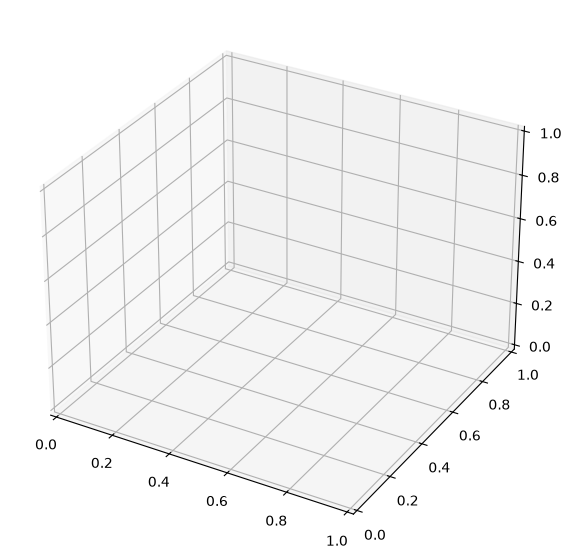

In [11]:
# In this section, I will create visualizations
df_reduced = pd.DataFrame(reduced, columns = ['x', 'y', 'z'])
df['text'] = text

fig = plt.figure(figsize = (10,7))
ax = fig.add_subplot(111, projection = '3d')
ax.scatter(df['x'], df['y'], df['z'])

for i, txt in enumerate(df['text']):
    ax.text(df['x'], df['y'][i], df['z'][i], txt)
    
ax.set_title('Visualization of Vectors in Space')
ax.set_xlabel('PCA 1')
ax.set_ylabel('PCA 2')
ax.set_zlabel('PCA 3')

plt.show()